# NOTEBOOK 04: PYTORCH DEEP LEARNING (MLP NEURAL NETWORK)
## Architecture
- Input: 8 features
- Layer 1: Linear(8, 64) + BatchNorm1d + ReLU + Dropout(0.2)
- Layer 2: Linear(64, 32) + BatchNorm1d + ReLU + Dropout(0.2)
- Layer 3: Linear(32, 1) Logits
- Loss: `BCEWithLogitsLoss` with `pos_weight = 10.76` (inverse class prevalence)


In [1]:
import os
import sys
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

sys.path.append(os.path.join("..", "training_scripts"))
from data_loader import prepare_splits
from train_dl import DiabetesMLP

data = prepare_splits()
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.14.0+cpu


### 4.1 Training PyTorch MLP with Epoch Monitoring

In [2]:
model = DiabetesMLP(input_dim=8)
pos_weight = torch.tensor([np.sum(y_train == 0) / (np.sum(y_train == 1) + 1e-5)], dtype=torch.float32)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32).unsqueeze(1))
val_ds = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32).unsqueeze(1))
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

epochs = 10
history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_recall': []}

for epoch in range(1, epochs + 1):
    model.train()
    t_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(bx), by)
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(bx)
    t_loss /= len(train_ds)
    
    model.eval()
    v_loss = 0.0
    val_preds, val_targets = [], []
    with torch.no_grad():
        for bx, by in val_loader:
            logits = model(bx)
            v_loss += criterion(logits, by).item() * len(bx)
            probs = torch.sigmoid(logits).cpu().numpy().flatten()
            val_preds.extend((probs >= 0.5).astype(int))
            val_targets.extend(by.cpu().numpy().flatten())
            
    v_loss /= len(val_ds)
    vf1 = f1_score(val_targets, val_preds)
    vrec = recall_score(val_targets, val_preds)
    
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['val_f1'].append(vf1)
    history['val_recall'].append(vrec)
    print(f"Epoch {epoch:02d} | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Val F1: {vf1:.4f} | Val Recall: {vrec:.4f}")


Epoch 01 | Train Loss: 0.6455 | Val Loss: 0.4665 | Val F1: 0.5515 | Val Recall: 0.8941


Epoch 02 | Train Loss: 0.4809 | Val Loss: 0.4231 | Val F1: 0.5787 | Val Recall: 0.8824


Epoch 03 | Train Loss: 0.4453 | Val Loss: 0.3956 | Val F1: 0.5723 | Val Recall: 0.9035


Epoch 04 | Train Loss: 0.4264 | Val Loss: 0.3782 | Val F1: 0.5713 | Val Recall: 0.9165


Epoch 05 | Train Loss: 0.4117 | Val Loss: 0.3666 | Val F1: 0.5776 | Val Recall: 0.9176


Epoch 06 | Train Loss: 0.4035 | Val Loss: 0.3607 | Val F1: 0.5845 | Val Recall: 0.9094


Epoch 07 | Train Loss: 0.3921 | Val Loss: 0.3581 | Val F1: 0.5952 | Val Recall: 0.9118


Epoch 08 | Train Loss: 0.3905 | Val Loss: 0.3562 | Val F1: 0.5969 | Val Recall: 0.9059


Epoch 09 | Train Loss: 0.3853 | Val Loss: 0.3512 | Val F1: 0.5876 | Val Recall: 0.9153


Epoch 10 | Train Loss: 0.3812 | Val Loss: 0.3510 | Val F1: 0.5901 | Val Recall: 0.9129


### 4.2 Training Dynamics Curves (Loss & Metric Convergence)

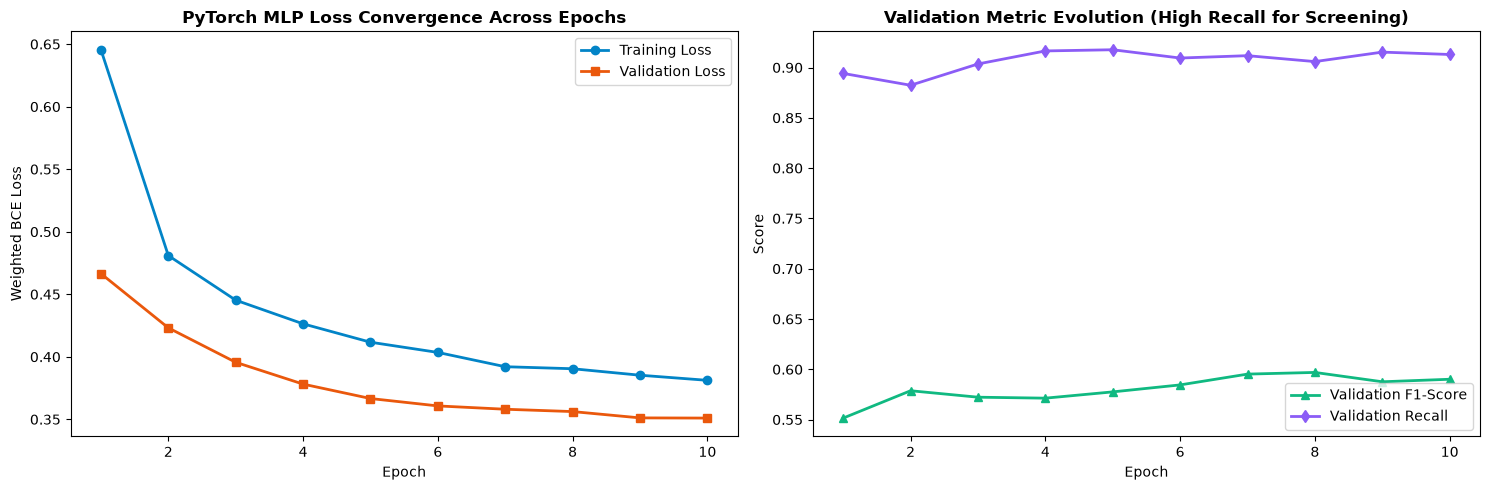

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss Curves
axes[0].plot(range(1, epochs + 1), history['train_loss'], 'o-', color='#0284c7', label='Training Loss', linewidth=2)
axes[0].plot(range(1, epochs + 1), history['val_loss'], 's-', color='#ea580c', label='Validation Loss', linewidth=2)
axes[0].set_title("PyTorch MLP Loss Convergence Across Epochs", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted BCE Loss")
axes[0].legend()

# Performance Evolution
axes[1].plot(range(1, epochs + 1), history['val_f1'], '^-', color='#10b981', label='Validation F1-Score', linewidth=2)
axes[1].plot(range(1, epochs + 1), history['val_recall'], 'd-', color='#8b5cf6', label='Validation Recall', linewidth=2)
axes[1].set_title("Validation Metric Evolution (High Recall for Screening)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

plt.tight_layout()
plt.show()


### 4.3 Output Probability Calibration & Separation Margin

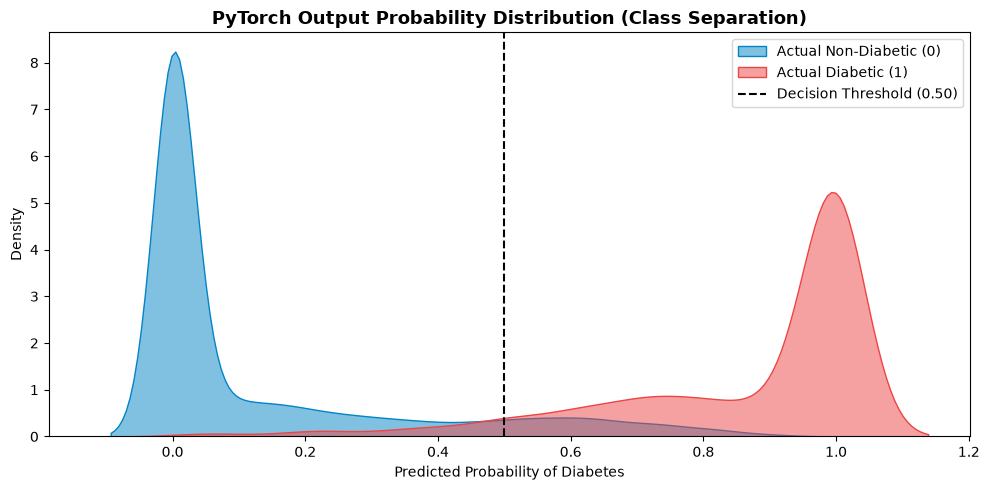

In [4]:
model.eval()
with torch.no_grad():
    test_logits = model(torch.tensor(X_test, dtype=torch.float32))
    test_probs = torch.sigmoid(test_logits).cpu().numpy().flatten()

plt.figure(figsize=(10, 5))
sns.kdeplot(test_probs[y_test == 0], color='#0284c7', fill=True, label='Actual Non-Diabetic (0)', alpha=0.5)
sns.kdeplot(test_probs[y_test == 1], color='#ef4444', fill=True, label='Actual Diabetic (1)', alpha=0.5)
plt.axvline(x=0.5, color='black', linestyle='--', label='Decision Threshold (0.50)')
plt.title("PyTorch Output Probability Distribution (Class Separation)", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Probability of Diabetes")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()
